In [ ]:
import time
import numpy as np, pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

df = pd.read_csv("../../Data/data_cleaning/cars_cleaned.csv")
print(df.shape) 
print(df.dtypes)
print(df.isna().sum())

(12494, 21)
list_id                  int64
subject                    str
price_million          float64
mfdate                   int64
car_age                  int64
odo_km                 float64
carbrand_name              str
carmodel_name              str
region_name                str
region_name_v3             str
area_name                  str
ward_name                  str
list_time                int64
flag_chinh_chu           int64
flag_bao_duong_hang      int64
gearbox                    str
fuel                       str
cartype                    str
carcolor                   str
carorigin                  str
carseats                   str
dtype: object
list_id                0
subject                0
price_million          0
mfdate                 0
car_age                0
odo_km                 0
carbrand_name          0
carmodel_name          0
region_name            0
region_name_v3         0
area_name              1
ward_name              7
list_time              

In [2]:
print(df.isna().sum().sum())          # total missing values, expect 0
text_cols = df.select_dtypes(exclude="number").columns
print(df[text_cols].nunique().sort_values())

8
gearbox               3
fuel                  4
cartype              10
carorigin            11
carseats             12
carcolor             13
region_name_v3       34
carbrand_name        55
region_name          63
carmodel_name       406
area_name           423
ward_name          1377
subject           12301
dtype: int64


In [3]:
num_cols = ["mfdate", "odo_km", "flag_chinh_chu", "flag_bao_duong_hang"]
cat_cols = ["carbrand_name", "carmodel_name", "region_name", "gearbox",
            "fuel", "cartype", "carcolor", "carorigin", "carseats"]

X = df[num_cols + cat_cols]
y = df["price_million"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(9995, 13) (2499, 13)


In [20]:
# 1) Where are the 8 missing values?
print(X_train.isna().sum()[lambda s: s > 0])
print(X_test.isna().sum()[lambda s: s > 0])

# 2) Preprocessing
#from sklearn.pipeline import Pipeline
#from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
#from sklearn.impute import SimpleImputer
#rom sklearn.preprocessing import OneHotEncoder
#from sklearn.ensemble import RandomForestRegressor
#from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=5)),
    ]), cat_cols),
])

# 3) Baseline Random Forest, trained on log(price)
rf = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", preprocess),
        ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    ]),
    func=np.log1p, inverse_func=np.expm1,
)
rf.fit(X_train, y_train)

# 4) Score on the test set (in million VND)
pred = rf.predict(X_test)
print("RMSE:", round(mean_squared_error(y_test, pred) ** 0.5, 1), "million")
print("MAE :", round(mean_absolute_error(y_test, pred), 1), "million")
print("R2  :", round(r2_score(y_test, pred), 3))

Series([], dtype: int64)
Series([], dtype: int64)
RMSE: 207.8 million
MAE : 76.6 million
R2  : 0.753


In [19]:
xgb = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", preprocess),
        ("model", XGBRegressor(n_estimators=500, learning_rate=0.05,
                               max_depth=6, random_state=42, n_jobs=-1)),
    ]),
    func=np.log1p, inverse_func=np.expm1,
)
xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)
print("RMSE:", round(mean_squared_error(y_test, pred_xgb) ** 0.5, 1), "million")
print("MAE :", round(mean_absolute_error(y_test, pred_xgb), 1), "million")
print("R2  :", round(r2_score(y_test, pred_xgb), 3))

RMSE: 205.3 million
MAE : 82.3 million
R2  : 0.759


In [14]:
def make(model):
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", preprocess), ("model", model)]),
        func=np.log1p, inverse_func=np.expm1,
    )

searches = {
    "rf": (make(RandomForestRegressor(random_state=42, n_jobs=-1)), {
        "regressor__model__n_estimators": [200, 400, 600],
        "regressor__model__max_depth": [None, 15, 25],
        "regressor__model__min_samples_leaf": [1, 2, 4],
        "regressor__model__max_features": ["sqrt", 0.5, 1.0],
    }),
    "xgb": (make(XGBRegressor(random_state=42, n_jobs=-1)), {
        "regressor__model__n_estimators": [300, 600, 900],
        "regressor__model__learning_rate": [0.03, 0.05, 0.1],
        "regressor__model__max_depth": [4, 6, 8],
        "regressor__model__subsample": [0.7, 0.9, 1.0],
        "regressor__model__colsample_bytree": [0.5, 0.8, 1.0],
    }),
}

best = {}
for name, (est, params) in searches.items():
    t0 = time.time()
    s = RandomizedSearchCV(est, params, n_iter=10, cv=3,
                           scoring="neg_root_mean_squared_error",
                           random_state=42, n_jobs=1, verbose=1)
    s.fit(X_train, y_train)
    best[name] = s.best_estimator_

    p = s.best_estimator_.predict(X_test)
    print(f"\n[{name}] best params: {s.best_params_}")
    print(f"[{name}] CV RMSE: {-s.best_score_:.1f} | time: {(time.time()-t0)/60:.1f} min")
    print(f"[{name}] TEST  RMSE: {mean_squared_error(y_test, p)**0.5:.1f} | "
          f"MAE: {mean_absolute_error(y_test, p):.1f} | R2: {r2_score(y_test, p):.3f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits

[rf] best params: {'regressor__model__n_estimators': 200, 'regressor__model__min_samples_leaf': 1, 'regressor__model__max_features': 1.0, 'regressor__model__max_depth': None}
[rf] CV RMSE: 209.4 | time: 3.9 min
[rf] TEST  RMSE: 207.8 | MAE: 76.6 | R2: 0.753
Fitting 3 folds for each of 10 candidates, totalling 30 fits

[xgb] best params: {'regressor__model__subsample': 0.7, 'regressor__model__n_estimators': 900, 'regressor__model__max_depth': 6, 'regressor__model__learning_rate': 0.1, 'regressor__model__colsample_bytree': 0.8}
[xgb] CV RMSE: 192.5 | time: 1.6 min
[xgb] TEST  RMSE: 189.7 | MAE: 70.1 | R2: 0.795


carmodel_name          0.497660
carbrand_name          0.288518
gearbox                0.048760
region_name            0.046166
fuel                   0.034768
cartype                0.026535
carorigin              0.016071
carseats               0.015683
carcolor               0.011779
mfdate                 0.011365
odo_km                 0.001569
flag_chinh_chu         0.000903
flag_bao_duong_hang    0.000223
dtype: float32


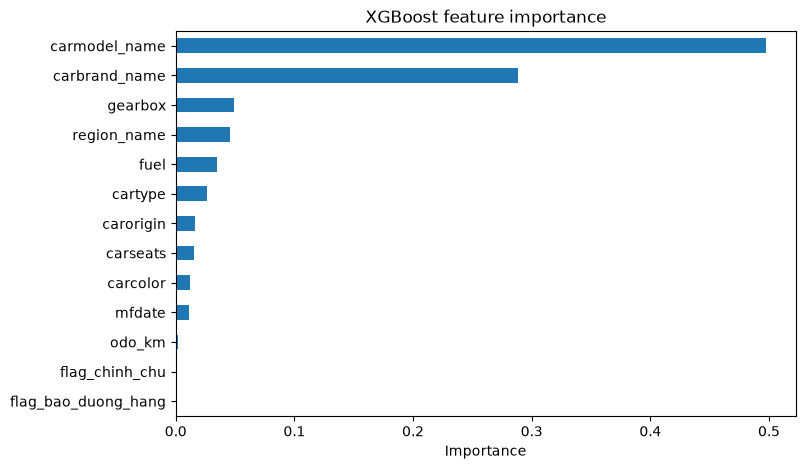

[372.  34. 146.]
[345.  25. 168.]


In [17]:
# 1) Save the winner. T09 loads this file.
joblib.dump(best["xgb"], "best_model.pkl")

# 2) Save the test set so T07/T08 teammates can evaluate on the same cars
X_test.assign(price_million=y_test).to_csv("test_set.csv", index=False)

# 3) Feature importance, grouped back to the original columns
pipe = best["xgb"].regressor_
names = pipe.named_steps["prep"].get_feature_names_out()
imp = pipe.named_steps["model"].feature_importances_

def original_col(n):
    n = n.split("__", 1)[1] if "__" in n else n
    for c in num_cols + cat_cols:
        if n == c or n.startswith(c + "_"):
            return c
    return n

imp_by_col = (pd.Series(imp, index=[original_col(n) for n in names])
                .groupby(level=0).sum().sort_values(ascending=False))
print(imp_by_col)

imp_by_col.sort_values().plot(kind="barh", figsize=(8, 5), title="XGBoost feature importance")
plt.xlabel("Importance")
plt.show()

# 4) Quick sanity check: reload the model and predict 3 test cars
m = joblib.load("best_model.pkl")
print(m.predict(X_test.head(3)).round(0))
print(y_test.head(3).values)

In [22]:
# Sanity check: reload the saved model and predict 3 test cars
m = joblib.load("best_model.pkl")
print(m.predict(X_test.head(3)).round(0))
print(y_test.head(3).values)

[372.  34. 146.]
[345.  25. 168.]


carbrand_name          229.9
mfdate                 168.9
carmodel_name           99.8
gearbox                 42.2
odo_km                  21.3
cartype                  8.0
fuel                     6.7
region_name              4.0
carseats                 3.3
carorigin                1.7
carcolor                 0.7
flag_chinh_chu           0.2
flag_bao_duong_hang     -0.0
dtype: float64


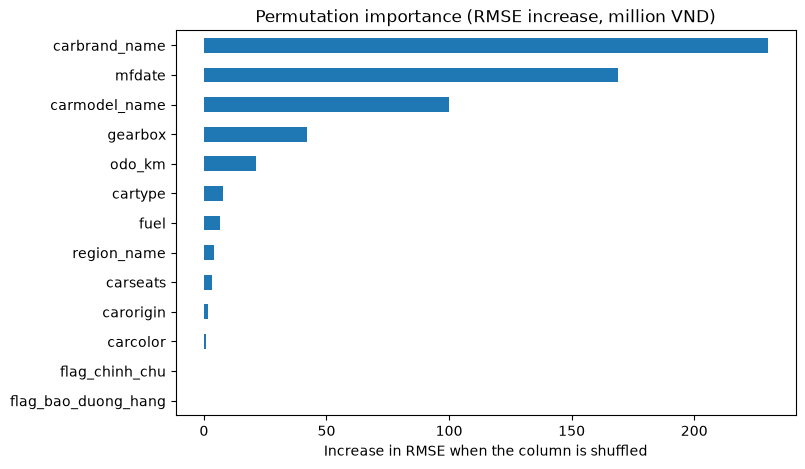

In [21]:
r = permutation_importance(best["xgb"], X_test, y_test, n_repeats=5,
                           scoring="neg_root_mean_squared_error",
                           random_state=42, n_jobs=1)
perm = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
print(perm.sort_values(ascending=False).round(1))

perm.plot(kind="barh", figsize=(8, 5), title="Permutation importance (RMSE increase, million VND)")
plt.xlabel("Increase in RMSE when the column is shuffled")
plt.show()

## T06 Results

| Model | RMSE (million) | MAE (million) | R² |
|---|---|---|---|
| Random Forest (baseline) | 207.8 | 76.6 | 0.753 |
| Random Forest (tuned) | 207.8 | 76.6 | 0.753 |
| XGBoost (baseline) | 205.3 | 82.3 | 0.759 |
| **XGBoost (tuned)** | **189.7** | **70.1** | **0.795** |

**Observations**
- Tuned XGBoost is the best model on all three metrics, so it is saved as `best_model.pkl`. Best parameters: n_estimators=900, learning_rate=0.1, max_depth=6, subsample=0.7, colsample_bytree=0.8.
- Tuning did not improve Random Forest: the search picked its default settings.
- The average error (MAE) is about 70 million VND. RMSE is larger (190 million) because the few very expensive cars are hard to predict.
- Both models were trained on log(price), following the T03 finding that price is right-skewed.
- Permutation importance on the test set shows brand, manufacture year and car model matter most, followed by gearbox and mileage. The two flag columns add almost nothing.
- Built-in XGBoost importance ranked year very low, which contradicts permutation importance. Built-in scores tend to favor columns with many categories, so permutation importance is the one we trust.
- Limitation: the model has not seen the very highest prices well, and no hyperparameter search was run beyond 10 random combinations.

In [10]:
err = (pd.Series(best["xgb"].predict(X_test), index=y_test.index) - y_test).abs()
print(err.groupby(pd.cut(y_test, [0, 300, 600, 1000, 20000])).agg(["count", "mean"]).round(1))

               count   mean
price_million              
(0, 300]         715   38.4
(300, 600]      1057   43.6
(600, 1000]      500   77.2
(1000, 20000]    227  278.4


In [11]:
pred = best["xgb"].predict(X_test)
pct = ((pd.Series(pred, index=y_test.index) - y_test).abs() / y_test * 100)
print(pct.groupby(pd.cut(y_test, [0, 300, 600, 1000, 20000])).mean().round(1))

price_million
(0, 300]         27.8
(300, 600]        9.9
(600, 1000]      10.1
(1000, 20000]    16.3
dtype: float64


- Limitation: the model is most accurate for cars between 300 and 1,000 million (about 10% average error). It is less accurate for cars under 300 million (about 28%) and above 1,000 million (about 16%). The absolute error is largest for cars above 1,000 million (about 278 million), and these 227 cars (9% of the test set) account for about a third of the total error, which is why RMSE (190) is much larger than MAE (70). Only 10 random hyperparameter combinations were tried per model.
- Predictions for very cheap or very expensive cars are less reliable than for mid-priced cars.